In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import scienceplots

plt.style.use("science")

import os
from ase.formula import Formula
import seaborn as sns

In [2]:
# First, we load all dataframes about cross validation, and merge them
all_dataframes = []
for clustering_model in ["pumkl", "copkmeans", "pckmeans", "kmeans"]:
    for scoring_model in ["svc"]:
        filename = f"{clustering_model}_150_clusters_{scoring_model}.csv"
        path = os.path.join("..","validation","cross_validation", clustering_model, filename)
        df = pd.read_csv(path, index_col=None)
        df["Clustering"] = clustering_model
        df["Scoring"] = scoring_model
        all_dataframes += [df]
df = pd.concat(all_dataframes, axis=0, ignore_index=True)

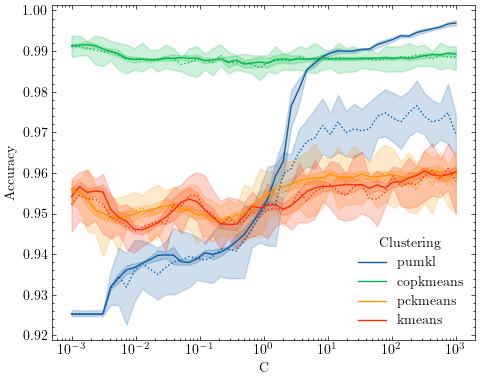

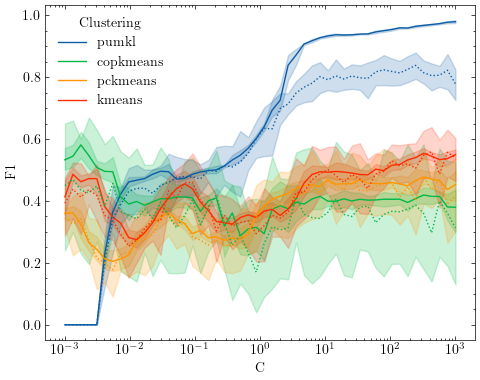

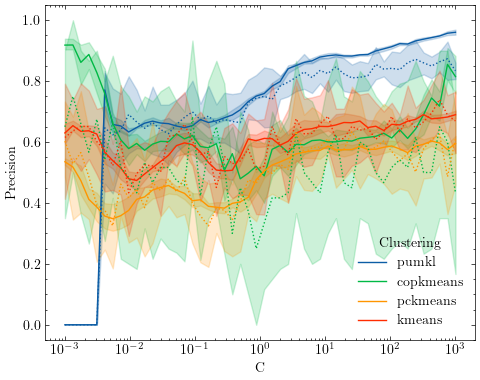

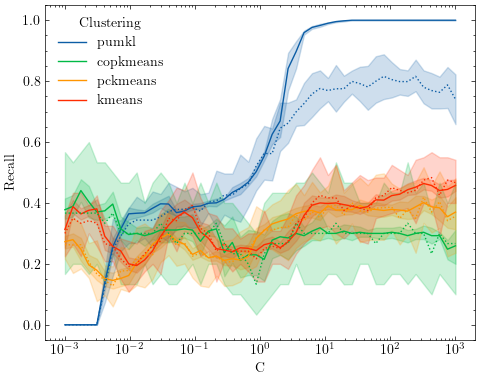

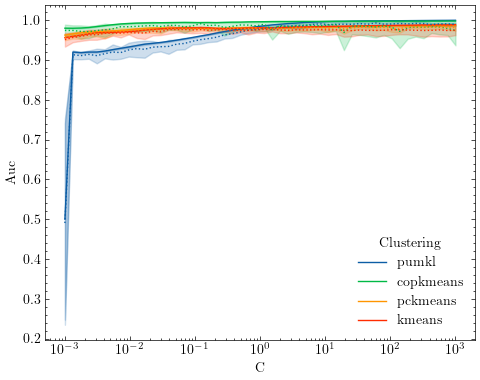

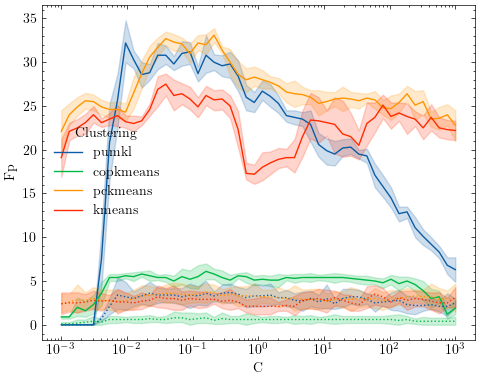

In [3]:
subdf = df[df.Scoring=="svc"]
for score in ["accuracy", "f1", "precision", "recall", "auc", "fp"]:
    plt.figure(figsize=(5,4))
    sns.lineplot(data=subdf, x="C", y=f"train_{score}", hue="Clustering", linestyle="-")
    sns.lineplot(data=subdf, x="C", y=f"test_{score}", hue="Clustering", linestyle=":", legend=False)
    plt.xscale("log")
    plt.xlabel("C")
    plt.ylabel(score.capitalize())
    plt.tight_layout()
    plt.savefig(f"svc_crossval_{score}.pdf")
    plt.show()